In [90]:
#Project 1: Titanic Survival Analysis

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [144]:
test_df=pd.read_csv(r"tested.csv")

In [145]:
test_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [146]:
test_df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,0,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


In [147]:
test_df.info

<bound method DataFrame.info of      PassengerId  Survived  Pclass  \
0            892         0       3   
1            893         1       3   
2            894         0       2   
3            895         0       3   
4            896         1       3   
..           ...       ...     ...   
413         1305         0       3   
414         1306         1       1   
415         1307         0       3   
416         1308         0       3   
417         1309         0       3   

                                             Name     Sex   Age  SibSp  Parch  \
0                                Kelly, Mr. James    male  34.5      0      0   
1                Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
2                       Myles, Mr. Thomas Francis    male  62.0      0      0   
3                                Wirz, Mr. Albert    male  27.0      0      0   
4    Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   
..                       

In [149]:
test_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [150]:
test_df['Age'].isnull().sum()

np.int64(86)

In [151]:
test_df['Age'].median()

np.float64(27.0)

In [155]:
test_df['Age']=test_df['Age'].fillna(test_df['Age'].median())

In [156]:
test_df['Age'].isnull().sum()

np.int64(0)

In [157]:
test_df['Fare'].isnull().sum()

np.int64(1)

In [158]:
test_df['Fare'].median()

np.float64(14.4542)

In [159]:
test_df['Fare']=test_df['Fare'].fillna(test_df['Fare'].median())

In [160]:
test_df['Fare'].isnull().sum()

np.int64(0)

In [161]:
test_df['Cabin'].isnull().sum()

np.int64(327)

In [164]:
test_df['Cabin']=test_df['Cabin'].fillna('Unknown')

In [165]:
test_df['Cabin'].isnull().sum()

np.int64(0)

Next task — check duplicate records
Now let's check whether your dataset contains duplicate rows.

Your task: Find the total number of duplicate rows in test_df.

In [175]:
test_df.duplicated().sum()

np.int64(0)

Next: Titanic Exploratory Data Analysis (EDA)
#Task 1 — Survival analysis
#Find how many passengers:
#- Survived (Survived = 1)
#- Did not survive (Survived = 0)

In [176]:
test_df['Survived'].value_counts()

Survived
0    266
1    152
Name: count, dtype: int64

— calculate survival percentage
Calculate the percentage of passengers who survived and did not survive.

Hint: Use the counts divided by the total number of passengers, multiplied by 100.

In [177]:
test_df['Survived'].value_counts()/len(test_df)*100

Survived
0    63.636364
1    36.363636
Name: count, dtype: float64

— survival by gender
Find how many male and female passengers survived.

Use groupby() with the Sex and Survived columns.

In [178]:
test_df.groupby('Sex')['Survived'].value_counts()

Sex     Survived
female  1           152
male    0           266
Name: count, dtype: int64

— survival by passenger class
Find the survival counts for each passenger class (Pclass).

In [180]:
test_df.groupby('Pclass')['Survived'].value_counts()

Pclass  Survived
1       0            57
        1            50
2       0            63
        1            30
3       0           146
        1            72
Name: count, dtype: int64

survival percentage by class
Calculate the survival percentage for each passenger class.

Hint: Use groupby('Pclass') and calculate the mean of Survived. Remember that Survived contains 1 for survived and 0 for not survived.

In [185]:
test_df.groupby('Pclass')['Survived'].mean()*100

Pclass
1    46.728972
2    32.258065
3    33.027523
Name: Survived, dtype: float64

Age analysis
Find the average age of passengers in your Titanic dataset.

In [186]:
test_df['Age'].mean()

np.float64(29.599282296650717)

— average age by survival status
Find the average age separately for:
- Passengers who did not survive (0)
- Passengers who survived (1)

In [187]:
test_df.groupby('Survived')['Age'].mean()

Survived
0    29.522218
1    29.734145
Name: Age, dtype: float64

In [188]:
test_df['Fare'].mean()

np.float64(35.57653540669856)

— average fare by survival status
Find the average fare separately for:
- Passengers who did not survive (0)
- Passengers who survived (1)

In [189]:
test_df.groupby('Survived')['Fare'].mean()

Survived
0    27.478728
1    49.747699
Name: Fare, dtype: float64

Seaborn visualization
Task 1 — Survival count plot
Create a Seaborn countplot showing:
- X-axis: Survived
- Y-axis: passenger count
- Title: Titanic Survival Count
Use your existing test_df DataFrame and Matplotlib.

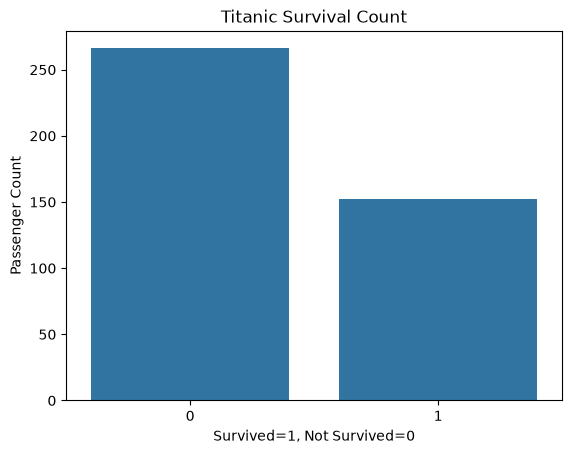

In [201]:
sns.countplot( x='Survived', data=test_df)
plt.title('Titanic Survival Count')
plt.xlabel('Survived=1, Not Survived=0')
plt.ylabel('Passenger Count')
plt.show()

Next task — Survival by gender
Create a count plot showing survival counts by gender.

Requirements:
- X-axis: Sex
- Use hue='Survived' to distinguish survived and not survived.
- Add title: Survival by Gender.
- Display the chart.

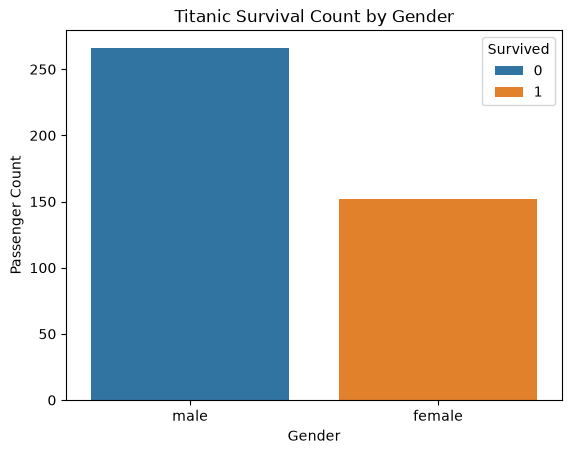

In [202]:
sns.countplot(x='Sex',hue='Survived',data=test_df)
plt.title('Titanic Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Passenger Count')
plt.show()

Next task — Survival by Passenger Class
Create a count plot with:
- X-axis: Pclass
- Hue: Survived
- Title: Survival by Passenger Class
- X-axis label: Passenger Class
- Y-axis label: Passenger Count


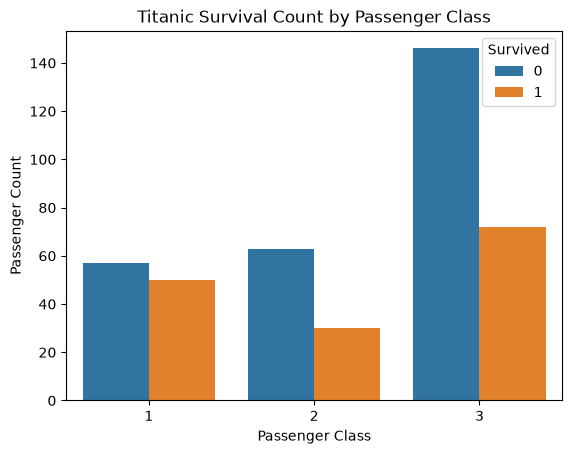

In [203]:
sns.countplot(x='Pclass',hue='Survived',data=test_df)
plt.title('Titanic Survival Count by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Passenger Count')
plt.show()

Age distribution
Create a histogram to understand the age distribution of Titanic passengers.

Requirements:
- Use sns.histplot()
- Data column: Age
- Use 20 bins.
- Add a KDE curve (kde=True).
- Title: Age Distribution of Titanic Passengers
- X-axis: Age
- Y-axis: Frequency

AttributeError: Rectangle.set() got an unexpected keyword argument 'KDE'

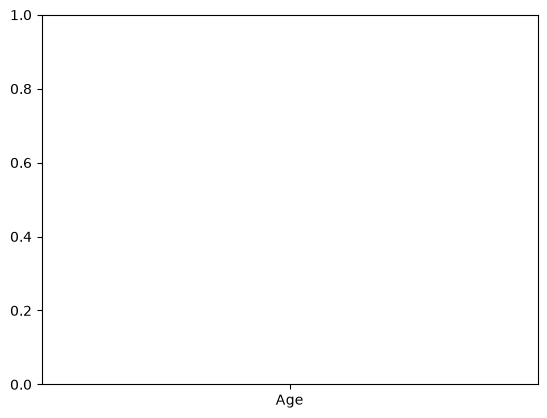

In [ ]:
sns.histplot(data=test_df, x='Age', bins=20, kde=True)
plt.title('Age Distribution of Passengers')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()